# Détection de toxicité dans le chat de League of Legends

## Objectif
Construire un classifieur binaire qui associe à chaque message la probabilité d'être **toxique**. Le jeu de données est `Juchen/league-toxicity-chat` et fournit déjà les splits `train` et `validation`. Ce notebook est aussi le protocole de sélection du modèle qui sera ensuite consommé par l'API et l'interface Streamlit/Django.

**Décision méthodologique.** Les messages sont courts, informels et riches en fautes, abréviations et termes propres à LoL. On conserve donc le texte presque brut : pas de stemming, lemmatisation, suppression de stop words ni correction orthographique. Ces transformations peuvent détruire précisément les signaux utiles (`diff`, répétitions de lettres, insultes masquées). La mise en minuscules est laissée à TF-IDF pour réduire la sparsité; les n-grams de caractères capturent en complément les variantes orthographiques.

Le notebook compare : (1) une baseline majoritaire, (2) TF-IDF de mots + régression logistique, (3) TF-IDF de mots + SVM linéaire calibré, (4) mots + caractères + régression logistique, et (5) un BiLSTM. La performance principale est la **PR-AUC** puis le F1 de la classe toxique, plus informatifs que l'accuracy lorsque la toxicité est minoritaire.

## 1. Installation et reproductibilité

Exécuter une fois dans l'environnement du projet : `python -m pip install -r requirements.txt`. Le téléchargement du dataset requiert une connexion Hugging Face. Le seed fixe les composantes aléatoires, sans garantir une reproductibilité bit à bit de TensorFlow sur tous les systèmes.

In [31]:
from pathlib import Path
import json
import random
import re
import warnings

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from datasets import load_dataset
from sklearn.calibration import CalibratedClassifierCV
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    ConfusionMatrixDisplay, average_precision_score, brier_score_loss,
    classification_report, f1_score, precision_recall_curve,
    precision_score, recall_score, roc_auc_score,
)
from sklearn.pipeline import FeatureUnion, Pipeline
from sklearn.svm import LinearSVC
from sklearn.utils.class_weight import compute_class_weight
import tensorflow as tf

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.keras.utils.set_random_seed(SEED)
warnings.filterwarnings('ignore', category=FutureWarning)

ARTIFACTS_DIR = Path('../artifacts')
ARTIFACTS_DIR.mkdir(exist_ok=True)
sns.set_theme(style='whitegrid', context='notebook')

## 2. Chargement et contrôle de schéma

On utilise les splits publiés : le `validation` n'est jamais utilisé lors de l'ajustement des modèles classiques. Les variables `id`, `source` et `category` sont volontairement exclues des prédicteurs : elles peuvent décrire la provenance ou l'annotation et donner une performance artificiellement élevée, alors que l'application ne recevra qu'un texte.

In [32]:
DATASET_REPO = 'Juchen/league-toxicity-chat'
raw = load_dataset(DATASET_REPO)
print(raw)
assert {'train', 'validation'}.issubset(raw.keys()), 'Les splits train et validation sont attendus.'

train = raw['train'].to_pandas().copy()
valid = raw['validation'].to_pandas().copy()
print(f'train : {train.shape[0]:,} lignes | validation : {valid.shape[0]:,} lignes')
display(train.head())
print(train.dtypes)
assert {'message', 'label'}.issubset(train.columns), 'Colonnes message et label introuvables.'

DatasetDict({
    train: Dataset({
        features: ['id', 'message', 'label', 'source', 'category'],
        num_rows: 11595
    })
    validation: Dataset({
        features: ['id', 'message', 'label', 'source', 'category'],
        num_rows: 1213
    })
})
train : 11,595 lignes | validation : 1,213 lignes


,id,message,label,source,category
0,15922,place,0,l2dtnh,None
1,t2-0323,bot lane flaming each other again,0,teacher,quote_or_report
2,3971,i had an dc,0,l2dtnh,None
3,15943,gank,0,l2dtnh,None
4,2614,lolooo,0,l2dtnh,None


id          object
message     object
label        int64
source      object
category    object
dtype: object


In [33]:
# Audit minimal, avant toute transformation.
for name, frame in {'train': train, 'validation': valid}.items():
    print(f'\n{name}')
    print('Valeurs manquantes :')
    display(frame[['message', 'label']].isna().sum().to_frame('n'))
    print('Distribution du label :')
    display(frame['label'].value_counts(dropna=False).sort_index().to_frame('n'))

# Vérifie que la convention de classe est identique dans les deux splits.
print('Labels train :', sorted(train['label'].dropna().unique()))
print('Labels validation :', sorted(valid['label'].dropna().unique()))
assert set(train['label'].dropna().unique()) == {0, 1}
assert set(valid['label'].dropna().unique()) == {0, 1}

# Les doublons exacts entre splits créent une fuite d'évaluation.
train_messages = set(train['message'].dropna().astype(str).str.strip())
valid_messages = set(valid['message'].dropna().astype(str).str.strip())
print('Doublons exacts train/validation :', len(train_messages & valid_messages))
print('Doublons internes train :', train['message'].duplicated().sum())
print('Doublons internes validation :', valid['message'].duplicated().sum())


train
Valeurs manquantes :


,n
message,0
label,0


Distribution du label :


,n
label,
0,10320
1,1275



validation
Valeurs manquantes :


,n
message,0
label,0


Distribution du label :


,n
label,
0,1101
1,112


Labels train : [0, 1]
Labels validation : [0, 1]
Doublons exacts train/validation : 195
Doublons internes train : 2849
Doublons internes validation : 192


n_chars                                             n_tokens_approx  \
         count   mean    std  min   25%   50%   75%    max           count   
label                                                                        
0      10320.0  12.58  11.54  1.0   4.0   9.0  17.0  204.0         10320.0   
1       1275.0  21.24  13.87  2.0  11.0  19.0  28.5  117.0          1275.0   

                                             
       mean   std  min  25%  50%  75%   max  
label                                        
0      2.91  2.36  1.0  1.0  2.0  4.0  38.0  
1      4.64  3.01  1.0  2.0  4.0  6.0  23.0

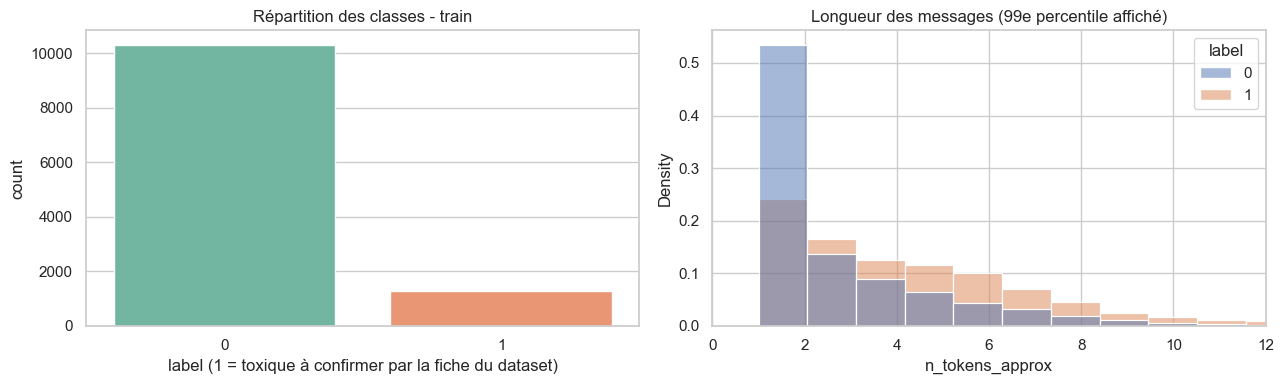

In [34]:
# Analyse des longueurs : les messages courts motivent les n-grams et un réseau compact.
for frame in (train, valid):
    frame['n_chars'] = frame['message'].fillna('').astype(str).str.len()
    frame['n_tokens_approx'] = frame['message'].fillna('').astype(str).str.split().str.len()

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
sns.countplot(data=train, x='label', ax=axes[0], hue='label', legend=False, palette='Set2')
axes[0].set_title('Répartition des classes - train')
axes[0].set_xlabel('label (1 = toxique à confirmer par la fiche du dataset)')
sns.histplot(data=train, x='n_tokens_approx', hue='label', bins=35, stat='density', common_norm=False, ax=axes[1])
axes[1].set_xlim(0, train['n_tokens_approx'].quantile(.99))
axes[1].set_title('Longueur des messages (99e percentile affiché)')
plt.tight_layout()
display(train.groupby('label')[['n_chars', 'n_tokens_approx']].describe().round(2))

## 3. Préparation du texte

La seule normalisation est structurelle : convertir une valeur manquante en chaîne vide, enlever les espaces superflus et uniformiser les URL et mentions. Il ne faut **pas** normaliser les vecteurs TF-IDF : leur norme est déjà gérée par le vectoriseur (`norm='l2'`). Pour le réseau, le `TextVectorization` apprend son vocabulaire uniquement sur `X_train`.

Les lignes vides sont retirées séparément dans chaque split, sans dédupliquer les textes : retirer sélectivement des doublons pourrait modifier artificiellement la distribution. Le nombre de lignes retirées est affiché.

In [35]:
def clean_message(value) -> str:
    text = '' if pd.isna(value) else str(value)
    text = re.sub(r'https?://\S+|www\.\S+', ' URL ', text)
    text = re.sub(r'@\w+', ' USER ', text)
    return re.sub(r'\s+', ' ', text).strip()

def make_xy(frame: pd.DataFrame):
    prepared = frame[['message', 'label']].dropna(subset=['label']).copy()
    prepared['message'] = prepared['message'].map(clean_message)
    before = len(prepared)
    prepared = prepared[prepared['message'].ne('')].copy()
    print(f'{before - len(prepared)} message(s) vide(s) retiré(s).')
    return prepared['message'], prepared['label'].astype(int)

X_train, y_train = make_xy(train)
X_valid, y_valid = make_xy(valid)
assert X_train.index.is_unique and X_valid.index.is_unique
print(X_train.head(3).tolist())

0 message(s) vide(s) retiré(s).
0 message(s) vide(s) retiré(s).
['place', 'bot lane flaming each other again', 'i had an dc']


## 4. Méthodes de machine learning

- **Dummy majoritaire** : niveau minimal à battre.
- **Mots TF-IDF + régression logistique** : baseline forte, rapide, avec probabilités natives.
- **Mots TF-IDF + SVM linéaire calibré** : le SVM est souvent très compétitif sur texte sparse; la calibration Platt fournit une probabilité exploitable par l'API.
- **Mots + caractères TF-IDF + régression logistique** : les caractères (3 à 5) rendent le modèle plus robuste aux fautes et aux insultes obfusquées.

`class_weight='balanced'` compense l'éventuel déséquilibre pendant l'apprentissage. La probabilité demeure à contrôler avec le Brier score; si le produit impose une probabilité parfaitement calibrée, on réservera un sous-ensemble de calibration distinct.

In [36]:
def make_word_tfidf():
    return TfidfVectorizer(ngram_range=(1, 2), min_df=2, max_df=0.98, sublinear_tf=True)

def make_char_tfidf():
    return TfidfVectorizer(analyzer='char_wb', ngram_range=(3, 5), min_df=2, sublinear_tf=True, max_features=80_000)

models = {
    'Dummy majoritaire': Pipeline([('tfidf', make_word_tfidf()), ('model', DummyClassifier(strategy='most_frequent'))]),
    'LogReg mots TF-IDF': Pipeline([
        ('tfidf', make_word_tfidf()),
        ('model', LogisticRegression(C=2.0, class_weight='balanced', max_iter=2_000, random_state=SEED)),
    ]),
    'SVM mots calibré': Pipeline([
        ('tfidf', make_word_tfidf()),
        ('model', CalibratedClassifierCV(LinearSVC(C=1.0, class_weight='balanced', random_state=SEED), method='sigmoid', cv=5)),
    ]),
    'LogReg mots + caractères': Pipeline([
        ('features', FeatureUnion([('word', make_word_tfidf()), ('char', make_char_tfidf())])),
        ('model', LogisticRegression(C=2.0, class_weight='balanced', max_iter=2_000, random_state=SEED)),
    ]),
}

def evaluate_probabilities(y_true, probas, model_name, threshold=0.5):
    pred = (probas >= threshold).astype(int)
    return {
        'modèle': model_name,
        'PR-AUC': average_precision_score(y_true, probas),
        'ROC-AUC': roc_auc_score(y_true, probas),
        'F1 toxique': f1_score(y_true, pred, zero_division=0),
        'précision toxique': precision_score(y_true, pred, zero_division=0),
        'rappel toxique': recall_score(y_true, pred, zero_division=0),
        'Brier': brier_score_loss(y_true, probas),
    }

ml_predictions = {}
ml_results = []
for name, pipeline in models.items():
    print(f'Entraînement : {name}')
    pipeline.fit(X_train, y_train)
    probas = pipeline.predict_proba(X_valid)[:, 1]
    ml_predictions[name] = probas
    ml_results.append(evaluate_probabilities(y_valid, probas, name))

ml_results = pd.DataFrame(ml_results).sort_values(['PR-AUC', 'F1 toxique'], ascending=False).reset_index(drop=True)
display(ml_results.round(3))

Entraînement : Dummy majoritaire
Entraînement : LogReg mots TF-IDF
Entraînement : SVM mots calibré
Entraînement : LogReg mots + caractères


,modèle,PR-AUC,ROC-AUC,F1 toxique,précision toxique,rappel toxique,Brier
0,LogReg mots + caractères,0.723,0.928,0.635,0.571,0.714,0.061
1,LogReg mots TF-IDF,0.688,0.896,0.593,0.503,0.723,0.078
2,SVM mots calibré,0.676,0.892,0.591,0.812,0.464,0.049
3,Dummy majoritaire,0.092,0.500,0.000,0.000,0.000,0.092


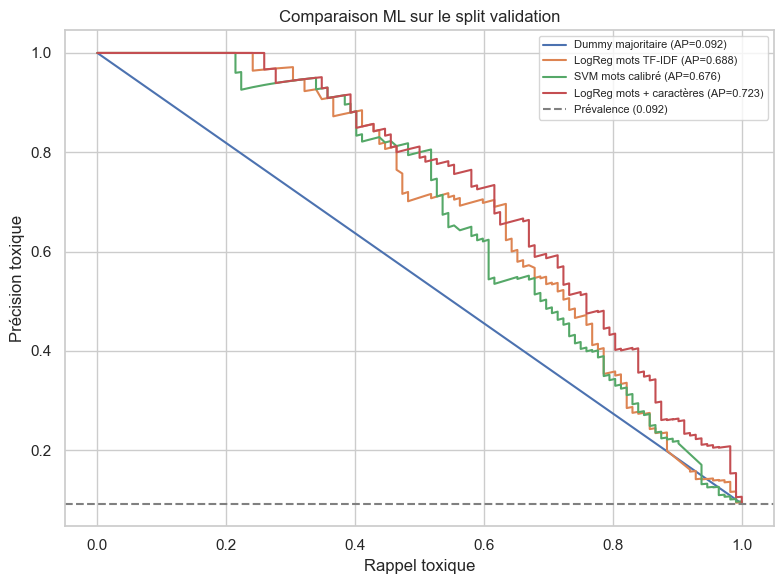

In [37]:
# Courbes PR : la référence horizontale est la prévalence de la classe toxique.
plt.figure(figsize=(8, 6))
for name, probas in ml_predictions.items():
    precision, recall, _ = precision_recall_curve(y_valid, probas)
    ap = average_precision_score(y_valid, probas)
    plt.plot(recall, precision, label=f'{name} (AP={ap:.3f})')
plt.axhline(y_valid.mean(), ls='--', c='grey', label=f'Prévalence ({y_valid.mean():.3f})')
plt.xlabel('Rappel toxique')
plt.ylabel('Précision toxique')
plt.title('Comparaison ML sur le split validation')
plt.legend(fontsize=8)
plt.tight_layout()

## 5. Méthode de deep learning : BiLSTM

Le BiLSTM lit la séquence de tokens dans les deux sens, ce qui peut modéliser des combinaisons de mots non vues comme n-gram exact. Il reste volontairement compact car ~12 000 messages ne justifient pas l'entraînement d'un gros Transformer à partir de zéro. `EarlyStopping` surveille la validation pour limiter le surapprentissage. LSTM est configuré avec `use_cudnn=False` : la variante cuDNN du GPU ne sait pas gérer le masque inversé produit par une couche bidirectionnelle avec padding; cette option est plus lente mais correcte et portable.

Pour une comparaison rigoureuse, la validation est ici utilisée pour l'arrêt anticipé et l'évaluation : les résultats DL doivent donc être interprétés avec prudence. Pour une évaluation finale non biaisée, ajouter un test aveugle ou faire une validation croisée imbriquée.

In [39]:
VOCAB_SIZE = 20_000
length_at_95 = int(np.ceil(X_train.str.split().str.len().quantile(.95)))
SEQUENCE_LENGTH = max(16, min(length_at_95, 80))
print(f'Longueur de séquence retenue : {SEQUENCE_LENGTH} tokens (95e percentile, plancher 16, plafond 80).')

# Keras 3 refuse les tableaux NumPy dtype=object issus de pandas.
# Des tenseurs tf.string rendent le pipeline compatible avec TensorFlow/Keras récents.
X_train_tf = tf.constant(X_train.astype(str).to_numpy().reshape(-1, 1), dtype=tf.string)
X_valid_tf = tf.constant(X_valid.astype(str).to_numpy().reshape(-1, 1), dtype=tf.string)
y_train_tf = tf.constant(y_train.to_numpy(), dtype=tf.int32)
y_valid_tf = tf.constant(y_valid.to_numpy(), dtype=tf.int32)

vectorize = tf.keras.layers.TextVectorization(
    max_tokens=VOCAB_SIZE,
    output_mode='int',
    output_sequence_length=SEQUENCE_LENGTH,
    standardize='lower_and_strip_punctuation',
)
vectorize.adapt(tf.data.Dataset.from_tensor_slices(X_train_tf).batch(256))

classes = np.unique(y_train)
weights = compute_class_weight(class_weight='balanced', classes=classes, y=y_train)
class_weight = dict(zip(classes, weights))

dl_model = tf.keras.Sequential([
    tf.keras.Input(shape=(1,), dtype=tf.string),
    vectorize,
    tf.keras.layers.Embedding(VOCAB_SIZE, 96, mask_zero=True),
    # Sans cuDNN : indispensable avec le masque inversé du BiLSTM sur GPU.
    tf.keras.layers.Bidirectional(tf.keras.layers.LSTM(48, dropout=0.20, use_cudnn=False)),
    tf.keras.layers.Dense(32, activation='relu'),
    tf.keras.layers.Dropout(0.30),
    tf.keras.layers.Dense(1, activation='sigmoid'),
])
dl_model.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3), loss='binary_crossentropy', metrics=[tf.keras.metrics.AUC(curve='PR', name='pr_auc')])

callbacks = [tf.keras.callbacks.EarlyStopping(monitor='val_pr_auc', mode='max', patience=3, restore_best_weights=True)]
history = dl_model.fit(
    X_train_tf, y_train_tf,
    validation_data=(X_valid_tf, y_valid_tf),
    epochs=20, batch_size=64, class_weight=class_weight, callbacks=callbacks, verbose=1,
)
dl_probas = dl_model.predict(X_valid_tf, verbose=0).ravel()
dl_result = evaluate_probabilities(y_valid, dl_probas, 'BiLSTM')
display(pd.DataFrame([dl_result]).round(3))

# Le modèle contient TextVectorization : il peut recevoir une chaîne brute côté API/webapp.
keras_path = ARTIFACTS_DIR / 'toxicity_bilstm.keras'
dl_model.save(keras_path)
# Contrôle de l'artefact réellement écrit, avant son utilisation par l'application.
# Les opérations LSTM GPU peuvent différer très légèrement après rechargement :
# on vérifie donc le chargement et la validité des probabilités, pas une égalité bit à bit.
reloaded_dl_model = tf.keras.models.load_model(keras_path)
reloaded_probas = reloaded_dl_model.predict(X_valid_tf[:3], verbose=0).ravel()
assert reloaded_probas.shape == (3,)
assert np.isfinite(reloaded_probas).all()
assert ((0.0 <= reloaded_probas) & (reloaded_probas <= 1.0)).all()
print(f'Modèle Keras exporté et chargé avec succès : {keras_path.resolve()}')

Longueur de séquence retenue : 16 tokens (95e percentile, plancher 16, plafond 80).
Epoch 1/20


2026-11-19 11:18:43.403505: W tensorflow/core/framework/local_rendezvous.cc:404] Local rendezvous is aborting with status: OUT_OF_RANGE: End of sequence


 35/182 ━━━━━━━━━━━━━━━━━━━━ 1:21 555ms/step - loss: 0.6835 - pr_auc: 0.1760

KeyboardInterrupt: 

,modèle,PR-AUC,ROC-AUC,F1 toxique,précision toxique,rappel toxique,Brier
0,LogReg mots + caractères,0.723,0.928,0.635,0.571,0.714,0.061
1,BiLSTM,0.717,0.920,0.563,0.431,0.812,0.089
2,LogReg mots TF-IDF,0.688,0.896,0.593,0.503,0.723,0.078
3,SVM mots calibré,0.676,0.892,0.591,0.812,0.464,0.049
4,Dummy majoritaire,0.092,0.500,0.000,0.000,0.000,0.092


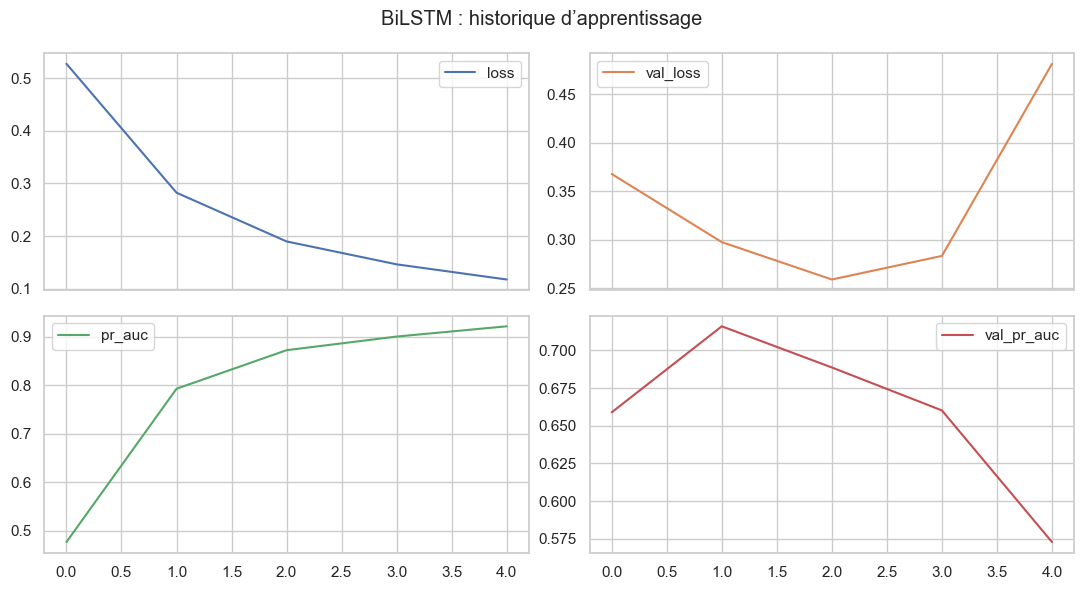

In [40]:
# Vérification visuelle de l'apprentissage (utile pour justifier early stopping).
pd.DataFrame(history.history)[['loss', 'val_loss', 'pr_auc', 'val_pr_auc']].plot(subplots=True, layout=(2, 2), figsize=(11, 6), title='BiLSTM : historique d’apprentissage')
plt.tight_layout()

all_results = pd.concat([ml_results, pd.DataFrame([dl_result])], ignore_index=True).sort_values(['PR-AUC', 'F1 toxique'], ascending=False).reset_index(drop=True)
display(all_results.round(3))

## 6. Choix du modèle, seuil et analyse d'erreurs

Le modèle retenu est celui ayant la meilleure PR-AUC; à écart négligeable, on privilégie le modèle le plus simple, le plus rapide et le mieux calibré. Ce critère doit être commenté après exécution avec les nombres affichés. Le seuil n'est pas nécessairement 0,50 : on le choisit sur la validation selon le F1 toxique. En production, ce seuil doit refléter le coût relatif d'un faux positif (censurer un message innocent) et d'un faux négatif (laisser passer une insulte).

Pour déployer immédiatement et conserver des probabilités simples à sérialiser, le bloc suivant sélectionne le meilleur modèle **ML**. Le BiLSTM est aussi exporté dans `toxicity_bilstm.keras` à la section précédente, avec sa vectorisation intégrée; l'API pourra donc charger l'artefact correspondant au modèle retenu.

Modèle ML exporté : LogReg mots + caractères
Seuil F1 optimal sur validation : 0.670
              precision    recall  f1-score   support

 non toxique      0.962     0.977     0.969      1101
     toxique      0.734     0.616     0.670       112

    accuracy                          0.944      1213
   macro avg      0.848     0.797     0.820      1213
weighted avg      0.941     0.944     0.942      1213



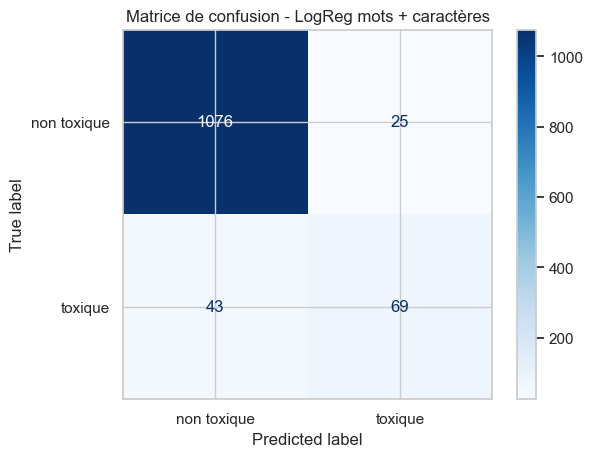

,message,label,probabilité_toxique,prediction
492,fucking loads of you to kill me XD,0,0.956938,1
1100,fk*,0,0.952105,1
1204,FKN 0,0,0.913541,1
785,the fuck],0,0.905043,1
36,so bad aim :D,0,0.881140,1
519,fuck,0,0.877279,1
894,fuking thx,0,0.870665,1
1027,so bad,0,0.858130,1
866,actually* im not retarded for the record,0,0.847955,1
102,in that suicide,0,0.844981,1


,message,label,probabilité_toxique,prediction
473,calm yo tits,1,0.017793,0
859,FDP,1,0.050471,0
953,dat nuubs,1,0.097669,0
139,skumbag.,1,0.098868,0
1140,lol cockscuekr dont talk pls,1,0.100442,0
1163,fidle ganked me 3 times early that fucked me,1,0.103970,0
838,fail ult,1,0.109347,0
1090,LEONA U DIED AT START,1,0.122592,0
453,bot cant 2vs 5,1,0.130391,0
199,haha so fed xin. gg top and bot,1,0.136145,0


In [41]:
# Sélection parmi les pipelines ML exportables; exclut la baseline Dummy.
deployable = ml_results[ml_results['modèle'] != 'Dummy majoritaire'].iloc[0]
selected_name = deployable['modèle']
selected_pipeline = models[selected_name]
selected_probas = ml_predictions[selected_name]

precision, recall, thresholds = precision_recall_curve(y_valid, selected_probas)
f1_by_threshold = 2 * precision * recall / np.maximum(precision + recall, 1e-12)
best_index = int(np.nanargmax(f1_by_threshold[:-1]))
best_threshold = float(thresholds[best_index])
print(f'Modèle ML exporté : {selected_name}')
print(f'Seuil F1 optimal sur validation : {best_threshold:.3f}')
print(classification_report(y_valid, (selected_probas >= best_threshold).astype(int), target_names=['non toxique', 'toxique'], digits=3))
ConfusionMatrixDisplay.from_predictions(y_valid, (selected_probas >= best_threshold).astype(int), display_labels=['non toxique', 'toxique'], cmap='Blues')
plt.title(f'Matrice de confusion - {selected_name}')
plt.show()

errors = pd.DataFrame({'message': X_valid, 'label': y_valid, 'probabilité_toxique': selected_probas})
errors['prediction'] = (errors['probabilité_toxique'] >= best_threshold).astype(int)
false_positives = errors[(errors.label == 0) & (errors.prediction == 1)].sort_values('probabilité_toxique', ascending=False)
false_negatives = errors[(errors.label == 1) & (errors.prediction == 0)].sort_values('probabilité_toxique')
display(false_positives.head(10))
display(false_negatives.head(10))

## 7. Export pour l'API et la webapp

Le pipeline exporté contient le prétraitement TF-IDF et le classifieur : l'API ne doit jamais reconstruire manuellement les features. `toxicity_metadata.json` documente explicitement le seuil et le sens des classes. **Ne jamais charger un fichier joblib non fiable** : seuls les artefacts produits par ce projet doivent être déployés.

Contrat d'inférence : entrée `message: str`; sortie `label` (0/1), `category` (`toxique`/`non toxique`), `probability_toxic` et `threshold`. Pour un fichier `.txt`, l'application doit traiter chaque ligne non vide comme un message, puis retourner une ligne de résultat par message.

In [42]:
model_path = ARTIFACTS_DIR / 'toxicity_pipeline.joblib'
metadata_path = ARTIFACTS_DIR / 'toxicity_metadata.json'
joblib.dump(selected_pipeline, model_path)
metadata = {
    'dataset': DATASET_REPO,
    'input_field': 'message',
    'positive_label': 1,
    'positive_category': 'toxique',
    'negative_category': 'non toxique',
    'threshold': round(best_threshold, 6),
    'selected_model': selected_name,
    'validation_metrics_at_0_5': {k: round(float(v), 6) for k, v in deployable.drop('modèle').items()},
}
metadata_path.write_text(json.dumps(metadata, ensure_ascii=False, indent=2), encoding='utf-8')

# Test de chargement : c'est exactement le chemin que suivra l'API.
reloaded = joblib.load(model_path)
example = 'bot lane flaming each other again'
proba = float(reloaded.predict_proba([clean_message(example)])[0, 1])
response = {
    'message': example,
    'label': int(proba >= best_threshold),
    'category': 'toxique' if proba >= best_threshold else 'non toxique',
    'probability_toxic': round(proba, 4),
    'threshold': round(best_threshold, 4),
}
print(json.dumps(response, ensure_ascii=False, indent=2))
print(f'Artifacts écrits : {model_path.resolve()} et {metadata_path.resolve()}')

{
  "message": "bot lane flaming each other again",
  "label": 0,
  "category": "non toxique",
  "probability_toxic": 0.4802,
  "threshold": 0.6701
}
Artifacts écrits : /Users/dre/Documents/GitHub/projet_ml_classification-Text/Projet-final-de-classification-de-textes/artifacts/toxicity_pipeline.joblib et /Users/dre/Documents/GitHub/projet_ml_classification-Text/Projet-final-de-classification-de-textes/artifacts/toxicity_metadata.json


## Conclusion à compléter après exécution

1. Reporter ici les métriques de `all_results` et retenir le modèle gagnant avec sa justification (performance, calibration, latence et taille).
2. Discuter les faux positifs et faux négatifs affichés : sarcasme, contexte absent, orthographe créative et messages très courts sont des limites attendues.
3. Le modèle classifie une ligne isolée et en anglais. Il ne doit pas décider seul d'une sanction joueur; il sert d'aide à la modération.
4. Avant une mise en production, mesurer la dérive des messages, versionner l'artefact et réévaluer sur un échantillon annoté récent.